# Experiment 3: Pipelined AES-256 Encryption Engine on the PYNQ-Z2

The FPGA holds a full AES-256 cipher: 14 rounds, one per pipeline stage, so a
block comes out 14 clock cycles after it goes in. The ARM processor loads the
key, writes a 128-bit block, and reads the encrypted block back over AXI4-Lite.

This notebook checks the engine against the official FIPS-197 test vector, then
encrypts and decrypts a message of its own.

Registers: `0x00` control (bit 0 encrypt, bit 1 decrypt, bit 2 load key),
`0x04` status, `0x20-0x2C` input block, `0x30-0x3C` output block,
`0x40` blocks processed, `0x50-0x6C` key (write only).

In [2]:
%matplotlib inline
from pynq import Overlay, MMIO
import matplotlib.pyplot as plt
import time

CTRL, STATUS, DATA_IN, DATA_OUT, BLOCKS, KEY = 0x00, 0x04, 0x20, 0x30, 0x40, 0x50

overlay = Overlay('system_wrapper.bit')
ip = overlay.ip_dict.get('aes_top_0/s_axi') or overlay.ip_dict['aes_top_0']
aes = MMIO(ip['phys_addr'], 0x1000)
print(f"Overlay loaded, AES engine at 0x{ip['phys_addr']:08X}")

def load_key(key):

    for i in range(8):
        aes.write(KEY + 4 * i, int.from_bytes(key[4 * i:4 * i + 4], 'big'))
    aes.write(CTRL, 0x4)
    while not aes.read(STATUS) & 0x4:
        pass

def process(block, decrypt=False):

    for i in range(4):
        aes.write(DATA_IN + 4 * i, int.from_bytes(block[4 * i:4 * i + 4], 'big'))
    aes.write(CTRL, 0x2 if decrypt else 0x1)
    while not aes.read(STATUS) & 0x2:
        pass
    return b''.join(aes.read(DATA_OUT + 4 * i).to_bytes(4, 'big') for i in range(4))


plaintext   00112233445566778899aabbccddeeff
ciphertext  8ea2b7ca516745bfeafc49904b496089
expected    8ea2b7ca516745bfeafc49904b496089
decrypted   00112233445566778899aabbccddeeff
encryption matches FIPS-197: PASS
decryption returns the input: PASS
message   : FPGA hardware encryption on the PYNQ-Z2 board!!!


In [3]:
KEY_VECTOR = bytes.fromhex('000102030405060708090a0b0c0d0e0f101112131415161718191a1b1c1d1e1f')
PLAIN      = bytes.fromhex('00112233445566778899aabbccddeeff')
EXPECTED   = bytes.fromhex('8ea2b7ca516745bfeafc49904b496089')

load_key(KEY_VECTOR)
cipher = process(PLAIN)
back   = process(EXPECTED, decrypt=True)

print('plaintext  ', PLAIN.hex())
print('ciphertext ', cipher.hex())
print('expected   ', EXPECTED.hex())
print('decrypted  ', back.hex())
print()
print('encryption matches FIPS-197:' , 'PASS' if cipher == EXPECTED else 'FAIL')
print('decryption returns the input:', 'PASS' if back == PLAIN else 'FAIL')


encrypted : 104615045468071bb2b9ae00f77888f8d96e29fa15d887ecfe101d854140b432be385b36418697c76e21e0d940642217
decrypted : FPGA hardware encryption on the PYNQ-Z2 board!!!
round trip: PASS
3 blocks encrypted in 0.8 ms (0.27 ms per block)
blocks processed since power up: 8


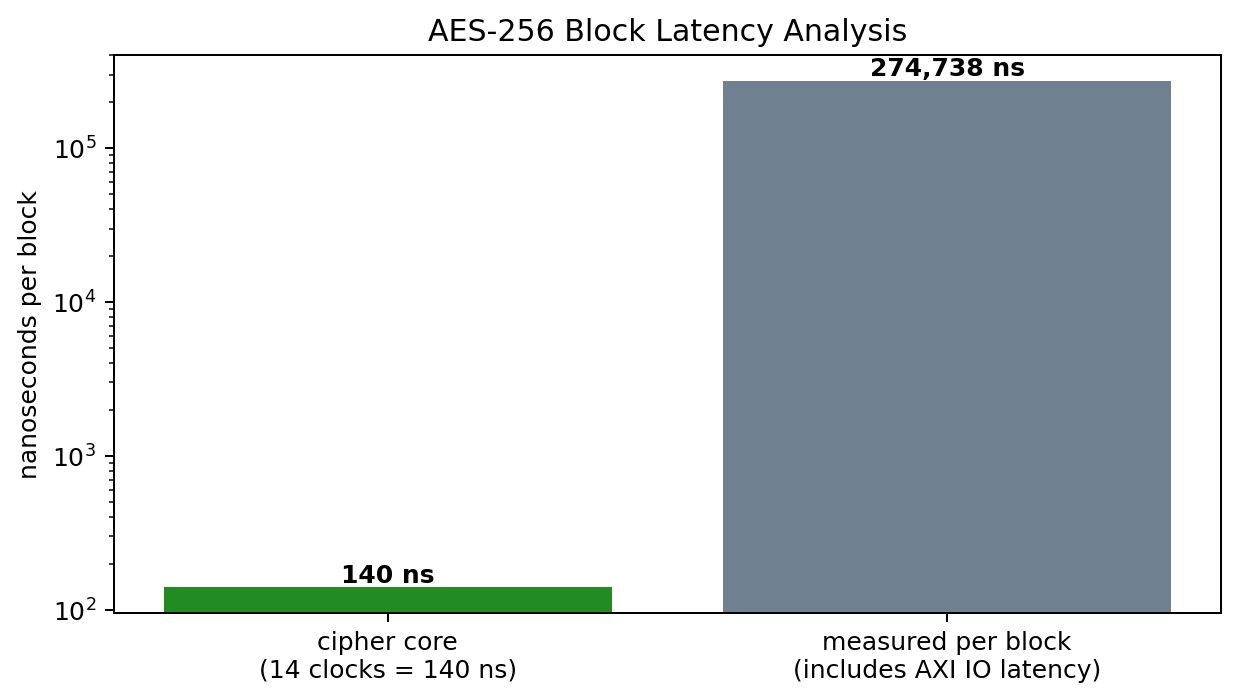

In [4]:
MESSAGE = b'FPGA hardware encryption on the PYNQ-Z2 board!!!'                               
SECRET_KEY = bytes(range(32))                                                 

load_key(SECRET_KEY)
blocks = [MESSAGE[i:i + 16] for i in range(0, len(MESSAGE), 16)]

start = time.time()
encrypted = [process(b) for b in blocks]
encrypt_time = time.time() - start

decrypted = b''.join(process(b, decrypt=True) for b in encrypted)

print('message   :', MESSAGE.decode())
print('encrypted :', b''.join(encrypted).hex())
print('decrypted :', decrypted.decode())
print()
print('round trip:', 'PASS' if decrypted == MESSAGE else 'FAIL')
print(f'{len(blocks)} blocks encrypted in {1000 * encrypt_time:.1f} ms '
      f'({1000 * encrypt_time / len(blocks):.2f} ms per block)')
print(f'blocks processed since power up: {aes.read(BLOCKS)}')
print()
print('Almost all of that time is the processor writing and reading registers:')
print('the cipher itself finishes a block in 14 clock cycles, or 140 ns at 100 MHz.')


In [ ]:
hardware_ns = 14 * 10                                                  
measured_ns = encrypt_time / len(blocks) * 1e9

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(['cipher itself\n(14 clocks)', 'measured per block\n(includes AXI reads/writes)'],
       [hardware_ns, measured_ns], color=['green', 'grey'])
ax.set_ylabel('nanoseconds per block')
ax.set_yscale('log')
ax.set_title('AES-256 block time')
for i, value in enumerate([hardware_ns, measured_ns]):
    ax.text(i, value, f'{value:,.0f} ns', ha='center', va='bottom')
plt.tight_layout()
plt.show()
